# ImageClassifierV2: analisi esplorativa del dataset (EDA)

In [`ImageClassifier.ipynb`](ImageClassifier.ipynb) abbiamo addestrato due reti per riconoscere **Marte** (il mio gatto) tra altri gatti, seguendo un tutorial. I risultati sul validation set:

| | CatClassifier (CNN da zero) | ResNet18 (transfer learning) |
|---|---|---|
| Precisione su Marte | 20.00% | 100.00% |
| Recall su Marte | 4.76% | 76.19% |

Prima di provare modelli più complessi (ad esempio un transformer) vale la pena fermarsi e farsi una domanda scomoda: **questi numeri misurano davvero la capacità di riconoscere Marte, o qualcos'altro?** Nel primo notebook il dataset è stato usato così com'era, senza mai guardarlo da vicino. In un progetto reale è il primo passo: un modello impara qualsiasi regolarità statistica distingua le classi, anche quelle che non c'entrano nulla con il problema (*garbage in, garbage out*).

### Le domande a cui vogliamo rispondere

1. Quanto è sbilanciato il dataset, e cosa implica per metriche e split?
2. Le due classi hanno caratteristiche "tecniche" diverse (dimensioni, orientamento, formato, compressione)?
3. Ci sono file anomali o duplicati che possono falsare l'addestramento o la valutazione?
4. Colori e luminosità sono diversi tra le classi? È un segnale legittimo o di contesto?
5. Cosa vede davvero la rete dopo il preprocessing?
6. **Esiste una scorciatoia**, cioè un modo di separare le classi senza guardare il gatto?

### Approccio

Si procede dal più economico al più costoso: prima i **metadati** (leggere solo l'intestazione dei file è velocissimo), poi i **pixel**, infine un **test della scorciatoia** con modelli che non vedono mai il gatto. Ogni sezione segue lo stesso schema: *perché lo guardiamo*, *cosa troviamo*, *cosa ne deduciamo*.

**Indice**
0. Setup
1. Inventario: una riga per immagine
2. Bilanciamento delle classi
3. Dimensioni e orientamento
4. Formato dei file e anomalie
5. Duplicati e quasi-duplicati
6. Colori, luminosità e saturazione
7. Cosa vede davvero la rete
8. Test della scorciatoia
9. Esperimento sui pixel: ricompressione controllata
10. Conclusioni e piano per i prossimi esperimenti

## 0. Setup

Usiamo solo librerie già presenti nel progetto: `pandas`/`numpy` per le tabelle, `PIL` per leggere le immagini, `matplotlib` per i grafici, `scikit-learn` per il test della scorciatoia e `torch`/`torchvision` solo per riprodurre esattamente lo split e il preprocessing del primo notebook.

I colori dei grafici sono fissi per tutto il notebook: **blu = altro gatto**, **arancione = Marte**. La coppia è stata verificata per essere distinguibile anche da chi ha difficoltà a distinguere i colori.

In [1]:
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torchvision import datasets, transforms

DATA_DIR = Path("../drive") #Stessa cartella usata in ImageClassifier.ipynb

#Nomi leggibili per le classi e colori fissi (blu = altro gatto, arancione = Marte)
NOMI = {"00_othercat": "altro gatto", "01_marte": "Marte"}
COLORI = {"altro gatto": "#2a78d6", "Marte": "#eb6834"}
CLASSI = ["altro gatto", "Marte"]

#Stile dei grafici: griglia leggera, niente bordi superflui, testo in grigio scuro
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#b9b8b3", "axes.labelcolor": "#52514e", "text.color": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e5e4e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False, "font.size": 10,
})
pd.set_option("display.precision", 3)

## 1. Inventario: una riga per immagine

**Perché.** Per analizzare un dataset di immagini conviene prima trasformarlo in una **tabella**, con una riga per immagine e una colonna per ogni proprietà. Da lì in avanti ogni domanda diventa un `groupby` o un grafico.

Due scelte importanti:
- Partiamo da `datasets.ImageFolder(...).samples`, cioè **la stessa lista, nello stesso ordine**, usata dal primo notebook. Così l'indice di ogni riga coincide con l'indice usato da `random_split` e potremo verificare cosa è finito in training e cosa in validation.
- `Image.open` in PIL è *lazy*: legge solo l'intestazione del file, non decodifica i pixel. Dimensioni, formato e modalità colore costano quindi pochissimo. Calcoliamo anche l'**MD5** dei byte del file, che servirà per trovare i duplicati esatti.

In [2]:
cartelle = datasets.ImageFolder(DATA_DIR) #Senza transform: ci servono solo percorsi ed etichette

righe = []
for indice, (percorso, etichetta) in enumerate(cartelle.samples):
    percorso = Path(percorso)
    dati = percorso.read_bytes()
    with Image.open(percorso) as img: #Legge solo l'intestazione, non i pixel
        righe.append({
            "indice": indice, #Indice usato da ImageFolder e quindi da random_split
            "classe": NOMI[cartelle.classes[etichetta]],
            "etichetta": etichetta,
            "file": percorso.name,
            "percorso": percorso,
            "larghezza": img.width,
            "altezza": img.height,
            "formato": img.format, #Formato reale letto dal contenuto, non dall'estensione
            "modalita": img.mode, #RGB, L (scala di grigi), P (palette)...
            "kb": len(dati) / 1024,
            "md5": hashlib.md5(dati).hexdigest(),
        })

df = pd.DataFrame(righe).set_index("indice")
df["rapporto"] = df.larghezza / df.altezza #Aspect ratio: >1 orizzontale, <1 verticale
df["lato_max"] = df[["larghezza", "altezza"]].max(axis=1)
df["megapixel"] = df.larghezza * df.altezza / 1e6
df["kb_per_mpx"] = df.kb / df.megapixel #Quanti KB servono per un milione di pixel: misura quanto è compresso il file
df["orientamento"] = np.select([df.rapporto < 0.95, df.rapporto > 1.05], ["verticale", "orizzontale"], "quadrata")

print(df.shape[0], "immagini,", df.shape[1], "colonne")
df.drop(columns=["percorso", "md5"]).head()

2207 immagini, 15 colonne


,classe,etichetta,file,larghezza,altezza,formato,modalita,kb,rapporto,lato_max,megapixel,kb_per_mpx,orientamento
indice,,,,,,,,,,,,,
0,altro gatto,0,10009.jpg,473,500,JPEG,RGB,21.357,0.946,500,0.236,90.306,verticale
1,altro gatto,0,10015.jpg,500,340,JPEG,RGB,18.717,1.471,500,0.170,110.099,orizzontale
2,altro gatto,0,10017.jpg,500,281,JPEG,RGB,20.664,1.779,500,0.141,147.075,orizzontale
3,altro gatto,0,10031.jpg,500,375,JPEG,RGB,21.479,1.333,500,0.188,114.552,orizzontale
4,altro gatto,0,10036.jpg,300,264,JPEG,RGB,17.928,1.136,300,0.079,226.360,orizzontale


## 2. Bilanciamento delle classi

**Perché.** La proporzione tra le classi decide quali metriche hanno senso, come dividere i dati e quanto saranno affidabili i risultati.

,immagini,percentuale
classe,,
altro gatto,2111,95.65
Marte,96,4.35


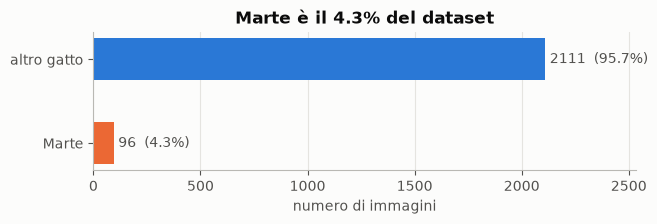

Accuratezza rispondendo sempre 'altro gatto': 95.65%


In [3]:
conteggi = df.classe.value_counts().reindex(CLASSI)
tabella = pd.DataFrame({"immagini": conteggi, "percentuale": (conteggi / len(df) * 100).round(2)})
display(tabella)

fig, ax = plt.subplots(figsize=(7, 1.8))
ax.barh(CLASSI, conteggi.values, color=[COLORI[c] for c in CLASSI], height=0.5)
for i, n in enumerate(conteggi.values):
    ax.text(n + 20, i, f"{n}  ({n / len(df):.1%})", va="center", color="#52514e") #Etichetta diretta: niente legenda necessaria
ax.set_xlim(0, conteggi.max() * 1.2)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("numero di immagini")
ax.set_title("Marte è il 4.3% del dataset")
plt.show()

print(f"Accuratezza rispondendo sempre 'altro gatto': {conteggi['altro gatto'] / len(df):.2%}")

**Cosa troviamo.** 2111 immagini di altri gatti contro 96 di Marte: un rapporto di circa **22 a 1**. Un modello che risponde sempre "altro gatto" ha il **95.65% di accuratezza** senza aver imparato niente.

**Cosa ne deduciamo.**
- **L'accuratezza non serve.** Le metriche da guardare sono **precisione** e **recall sulla classe Marte** (e l'F1, che le combina). Per confrontare modelli è utile anche l'area sotto la curva precision-recall, che non dipende da una soglia fissa.
- **Le metriche saranno rumorose.** Con un validation set del 20% le foto di Marte sono circa 20: ogni foto riconosciuta o persa sposta il recall di circa **5 punti percentuali**. Una differenza di 5-10 punti tra due modelli può essere puro caso. La soluzione è la **cross-validation stratificata** (ripetere la valutazione su 5 divisioni diverse e fare la media), o almeno più split con seed diversi.
- **Lo split va stratificato.** `random_split` non garantisce le proporzioni: con un'altra estrazione Marte potrebbe avere 12 o 28 foto nel validation set. `train_test_split(..., stratify=etichette)` di scikit-learn mantiene il 4.3% in entrambe le parti.
- **In addestramento serve compensare**, ad esempio pesando le classi nella loss o sovracampionando Marte.

## 3. Dimensioni e orientamento

**Perché.** Le immagini vengono tutte ridimensionate a 224×224, quindi sembra che le dimensioni originali non contino. Ma se le due classi provengono da **fonti diverse** (fotocamera, app, dataset pubblico), le dimensioni lo rivelano. E qualunque differenza sistematica tra le classi è un candidato a diventare una scorciatoia.

In [4]:
df.groupby("classe")[["larghezza", "altezza", "lato_max", "rapporto"]].describe().T.loc[
    (slice(None), ["min", "25%", "50%", "75%", "max"]), CLASSI]

classe         altro gatto    Marte
larghezza min      133.000  360.000
          25%      361.500  450.000
          50%      500.000  593.500
          75%      500.000  800.000
          max      500.000  800.000
altezza   min       84.000  244.000
          25%      333.000  533.000
          50%      375.000  800.000
          75%      387.500  800.000
          max      500.000  800.000
lato_max  min      147.000  671.000
          25%      500.000  800.000
          50%      500.000  800.000
          75%      500.000  800.000
          max      500.000  800.000
rapporto  min        0.370    0.450
          25%        1.042    0.562
          50%        1.333    0.742
          75%        1.333    1.501
          max        2.917    3.279

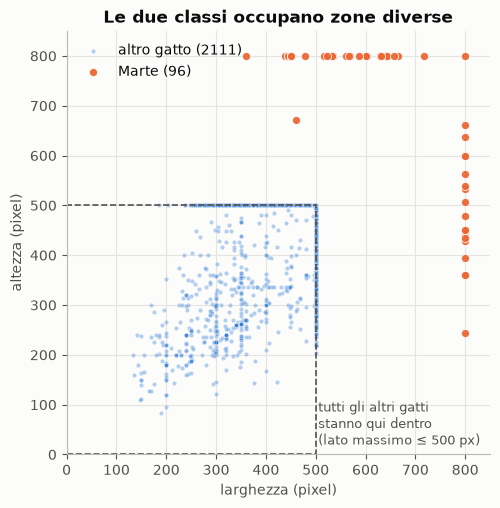

In [5]:
fig, ax = plt.subplots(figsize=(7, 5.5))
for classe, dimensione, alpha in [("altro gatto", 10, 0.35), ("Marte", 34, 0.95)]:
    sotto = df[df.classe == classe]
    ax.scatter(sotto.larghezza, sotto.altezza, s=dimensione, alpha=alpha, color=COLORI[classe],
               edgecolors="#fcfcfb", linewidths=0.6, label=f"{classe} ({len(sotto)})")
ax.add_patch(plt.Rectangle((0, 0), 500, 500, fill=False, ls="--", lw=1.2, ec="#52514e"))
ax.text(505, 20, "tutti gli altri gatti\nstanno qui dentro\n(lato massimo ≤ 500 px)", color="#52514e", fontsize=9)
ax.set_xlim(0, 850); ax.set_ylim(0, 850); ax.set_aspect("equal")
ax.set_xlabel("larghezza (pixel)"); ax.set_ylabel("altezza (pixel)")
ax.set_title("Le due classi occupano zone diverse")
ax.legend(loc="upper left")
plt.show()

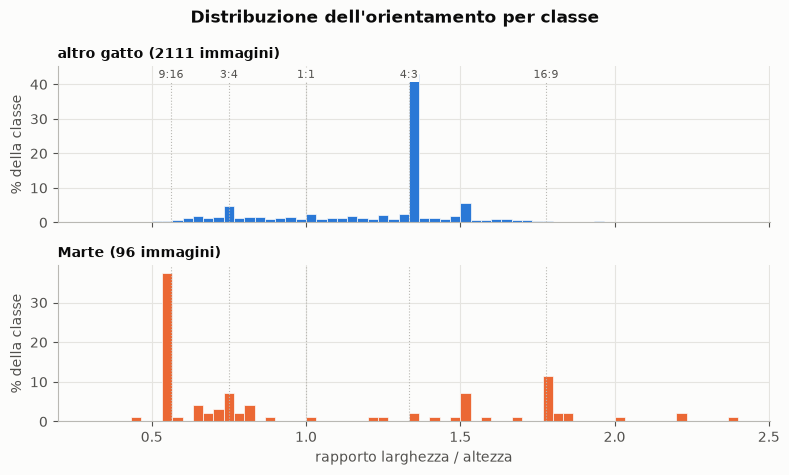

orientamento,orizzontale,quadrata,verticale
classe,,,
altro gatto,74.8,4.7,20.5
Marte,35.4,1.0,63.5


In [6]:
#Rapporti tipici: 9:16 e 3:4 (telefono in verticale), 1:1, 4:3 (fotocamere compatte, molti dataset), 16:9 (telefono in orizzontale)
RAPPORTI = {"9:16": 9 / 16, "3:4": 3 / 4, "1:1": 1, "4:3": 4 / 3, "16:9": 16 / 9}
bins = np.linspace(0.3, 2.4, 64)

fig, axes = plt.subplots(2, 1, figsize=(8, 4.8), sharex=True)
for ax, classe in zip(axes, CLASSI):
    sotto = df[df.classe == classe]
    #Percentuale della classe in ogni intervallo: con classi così sbilanciate i conteggi assoluti non sarebbero confrontabili
    ax.hist(sotto.rapporto.clip(upper=2.39), bins=bins, color=COLORI[classe],
            weights=np.full(len(sotto), 100 / len(sotto)), edgecolor="#fcfcfb", linewidth=0.5)
    for nome, valore in RAPPORTI.items():
        ax.axvline(valore, color="#b9b8b3", lw=0.8, ls=":")
    ax.set_ylabel("% della classe")
    ax.set_title(f"{classe} ({len(sotto)} immagini)", loc="left", fontsize=10)
for nome, valore in RAPPORTI.items():
    axes[0].text(valore, axes[0].get_ylim()[1] * 0.98, nome, ha="center", va="top", fontsize=8, color="#52514e",
                 bbox=dict(fc="#fcfcfb", ec="none", pad=1))
axes[-1].set_xlabel("rapporto larghezza / altezza")
fig.suptitle("Distribuzione dell'orientamento per classe", fontweight="bold")
plt.tight_layout()
plt.show()

(pd.crosstab(df.classe, df.orientamento, normalize="index") * 100).round(1).reindex(CLASSI)

**Cosa troviamo.**
- **Altri gatti**: il lato maggiore è sempre **al massimo 500 pixel** (mediana esattamente 500), e il rapporto più frequente è **4:3 orizzontale**. È la firma tipica di un dataset pubblico già ridimensionato in modo uniforme.
- **Marte**: **95 foto su 96 hanno il lato maggiore di 800 pixel** (l'ultima 671). I rapporti sono quelli di uno **smartphone**: 3:4 e 9:16 in verticale, 16:9 in orizzontale. Il 64% delle foto è verticale, contro il 20% degli altri gatti.
- Nel grafico a dispersione le due classi **non si sovrappongono affatto**: tutti gli altri gatti stanno dentro il quadrato 500×500, tutte le foto di Marte fuori.

**Cosa ne deduciamo.** Le due classi vengono da **due fonti diverse**: un dataset pubblico da una parte, le foto del mio telefono (probabilmente ridimensionate a 800 pixel da un'app o in fase di esportazione) dall'altra. Questo è un **confondente**: "essere Marte" e "essere una foto del mio telefono" sono la stessa cosa nel dataset, quindi un modello non ha modo di capire quale delle due imparare.

Il ridimensionamento a 224×224 cancella le dimensioni assolute, ma **non cancella il rapporto**: lo trasforma in una *deformazione* (sezione 7). E le distribuzioni del rapporto sono chiaramente diverse tra le due classi.

## 4. Formato dei file e anomalie

**Perché.** I file "strani" (formati inattesi, scala di grigi, animazioni) possono rompere la pipeline, oppure passare inosservati e introdurre altre differenze sistematiche tra le classi. Inoltre il **livello di compressione JPEG** lascia artefatti nei pixel, che una rete *potrebbe* imparare a riconoscere.

Il formato lo leggiamo da PIL, che lo ricava dal **contenuto** del file (i primi byte, detti *magic bytes*), non dall'estensione.

In [7]:
print(pd.crosstab([df.formato, df.modalita], df.classe).reindex(columns=CLASSI, fill_value=0))
anomalie = df[(df.formato != "JPEG") | (df.modalita != "RGB")]
anomalie[["classe", "file", "formato", "modalita", "larghezza", "altezza"]]

classe            altro gatto  Marte
formato modalita                    
GIF     P                   2      0
JPEG    L                   1      0
        RGB              2108     96


,classe,file,formato,modalita,larghezza,altezza
indice,,,,,,
373,altro gatto,11874.jpg,GIF,P,280,180
1614,altro gatto,7276.jpg,JPEG,L,295,226
2041,altro gatto,9565.jpg,GIF,P,250,187


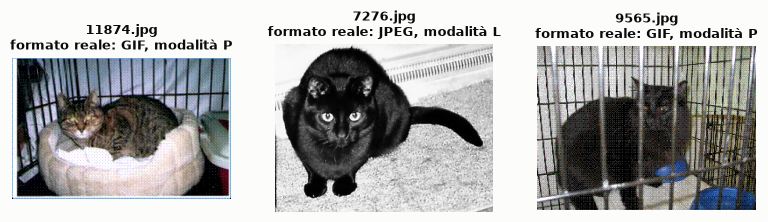

In [8]:
fig, axes = plt.subplots(1, len(anomalie), figsize=(3.2 * len(anomalie), 3))
for ax, (_, riga) in zip(axes, anomalie.iterrows()):
    with Image.open(riga.percorso) as img:
        ax.imshow(img.convert("RGB")) #Stessa conversione che fa ImageFolder quando carica le immagini
    ax.set_title(f"{riga.file}\nformato reale: {riga.formato}, modalità {riga.modalita}", fontsize=9)
    ax.axis("off")
plt.show()

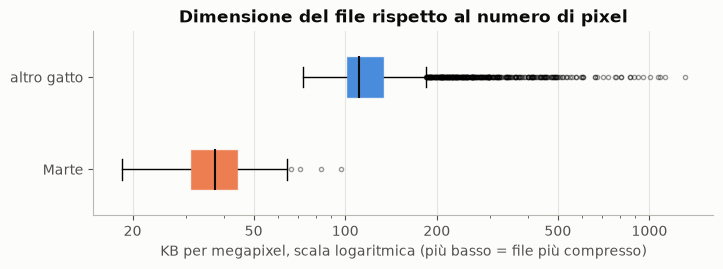

,kb,kb_per_mpx
classe,,
altro gatto,19.566,110.625
Marte,14.590,37.292


In [9]:
fig, ax = plt.subplots(figsize=(8, 2.4))
dati = [df.loc[df.classe == c, "kb_per_mpx"] for c in CLASSI]
box = ax.boxplot(dati, orientation="horizontal", tick_labels=CLASSI, widths=0.45, patch_artist=True, showfliers=True,
                 medianprops=dict(color="#0b0b0b", lw=1.5), flierprops=dict(marker="o", ms=3, alpha=0.4))
for patch, classe in zip(box["boxes"], CLASSI):
    patch.set_facecolor(COLORI[classe]); patch.set_alpha(0.85); patch.set_edgecolor("#fcfcfb")
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xscale("log") #Scala logaritmica: la coda lunga degli altri gatti schiaccerebbe i box
ax.set_xticks([20, 50, 100, 200, 500, 1000], ["20", "50", "100", "200", "500", "1000"])
ax.set_xlabel("KB per megapixel, scala logaritmica (più basso = file più compresso)")
ax.set_title("Dimensione del file rispetto al numero di pixel")
plt.show()

df.groupby("classe")[["kb", "kb_per_mpx"]].median().reindex(CLASSI)

I KB per megapixel sono però una misura **grezza** della compressione: dipendono anche dalla risoluzione e dal contenuto. Un'immagine piccola ha più dettaglio per pixel, quindi a parità di compressione richiede più byte per pixel di una grande. Visto che le due classi hanno risoluzioni diverse, questo confronto da solo non basta.

Per misurare la compressione **direttamente** leggiamo le **tabelle di quantizzazione** salvate dentro ogni JPEG. In breve:
- un JPEG divide l'immagine in blocchi 8×8 e divide ogni coefficiente per un valore della tabella: **valori più grandi = più informazione buttata = più compressione**;
- la libreria standard (libjpeg) costruisce la tabella scalando una tabella di riferimento in base alla **qualità** scelta (da 1 a 100);
- invertendo quella formula si stima la qualità con cui è stato salvato il file.

È una **stima**: alcuni programmi usano tabelle proprie. Come misura di confronto tra le classi però è affidabile.

In [10]:
#Tabella di quantizzazione di riferimento per la luminanza (standard JPEG, corrisponde alla qualità 50)
TABELLA_RIFERIMENTO = np.array([
    16, 11, 10, 16, 24, 40, 51, 61, 12, 12, 14, 19, 26, 58, 60, 55, 14, 13, 16, 24, 40, 57, 69, 56,
    14, 17, 22, 29, 51, 87, 80, 62, 18, 22, 37, 56, 68, 109, 103, 77, 24, 35, 55, 64, 81, 104, 113, 92,
    49, 64, 78, 87, 103, 121, 120, 101, 72, 92, 95, 98, 112, 100, 103, 99])

def qualita_jpeg(percorso):
    with Image.open(percorso) as img:
        tabelle = getattr(img, "quantization", None) #Solo i JPEG contengono tabelle di quantizzazione
    if not tabelle:
        return np.nan
    scala = np.sum(tabelle[0]) / TABELLA_RIFERIMENTO.sum() * 100 #Di quanto è stata "ingrandita" la tabella di riferimento
    return 5000 / scala if scala > 100 else (200 - scala) / 2 #Formula di libjpeg invertita: qualità < 50 se scala > 100

df["qualita_jpeg"] = [qualita_jpeg(p) for p in df.percorso]
print(df.groupby("classe").qualita_jpeg.describe().reindex(CLASSI).round(1).to_string())
print()
for classe in CLASSI:
    valori = df.loc[df.classe == classe, "qualita_jpeg"].round().value_counts().head(3)
    print(f"{classe}: qualità più frequenti", {int(q): int(n) for q, n in valori.items()})

              count  mean  std   min   25%   50%   75%   max
classe                                                      
altro gatto  2109.0  76.2  5.3  39.3  74.8  74.8  74.8  99.1
Marte          96.0  20.4  0.0  20.4  20.4  20.4  20.4  20.4

altro gatto: qualità più frequenti {75: 1775, 90: 72, 80: 53}
Marte: qualità più frequenti {20: 96}


**Cosa troviamo.**
- **Due file hanno estensione `.jpg` ma sono in realtà GIF** (`11874.jpg`, `9565.jpg`), in modalità palette (`P`). Un terzo file (`7276.jpg`) è in **scala di grigi** (`L`). Sono tutti e tre altri gatti.
- Le foto degli altri gatti pesano tutte **tra 17 e 22 KB**, qualunque sia la dimensione, e quasi tutte hanno qualità JPEG **75**: segno di una ricompressione uniforme fatta da chi ha costruito il dataset.
- **Tutte e 96 le foto di Marte hanno la stessa qualità JPEG stimata, circa 20**, cioè una compressione molto forte. Nessun altro gatto scende sotto 39. Anche i KB per megapixel vanno nella stessa direzione (mediana 37 contro 111), ma è la tabella di quantizzazione a dare la misura pulita.

**Cosa ne deduciamo.**
- **Mai fidarsi dell'estensione.** In una pipeline di produzione il formato va verificato dal contenuto. Qui non fa danni perché `ImageFolder` apre i file con PIL e li converte in RGB: le GIF diventano normali immagini a colori e quella in scala di grigi viene replicata su 3 canali identici. Con un caricatore che si basa sull'estensione, però, questi file genererebbero errori.
- **Nei metadati, la qualità JPEG stimata separa perfettamente le classi**, indipendentemente dalle dimensioni: le foto di Marte sono passate tutte dallo stesso programma (probabilmente un'app di messaggistica o di condivisione, che ricomprime in modo aggressivo e cancella i metadati EXIF). È un'**evidenza esplorativa**: ci dice che le due classi hanno avuto un trattamento diverso, non che un modello addestrato su queste immagini lo sfrutti.
- **A differenza delle dimensioni, la compressione lascia tracce nei pixel**: blocchi 8×8, bordi sfumati, colori "a chiazze". La riduzione a 224×224 le attenua (un blocco di 8 pixel diventa largo circa 2), ma non è detto che le cancelli del tutto. È quindi un'informazione **potenzialmente disponibile** alla rete: se e quanto la rete ne sia influenzata non si può stabilire dai metadati, ma solo con un esperimento sui pixel.
- **Non si può "togliere" la compressione** dalle foto di Marte: l'informazione persa non torna. L'unico modo per neutralizzarla è **degradare allo stesso modo anche gli altri gatti**, ricomprimendo tutte le immagini con la stessa qualità, oppure usare una compressione JPEG casuale come data augmentation in addestramento.

## 5. Duplicati e quasi-duplicati

**Perché.** Se la stessa foto (o quasi) finisce sia nel training sia nel validation set, la rete viene valutata su qualcosa che ha già visto: è un **data leakage** che gonfia le metriche. Con soli 96 esempi positivi basta una coppia "spezzata" per spostare il recall di 5 punti.

**Come.**
- **Duplicati esatti**: stesso MD5, cioè stessi byte.
- **Quasi-duplicati** (stessa scena scattata due volte, foto ricompressa o ridimensionata): l'MD5 non serve, perché basta un byte diverso per cambiarlo completamente. Usiamo un **hash percettivo**, il *difference hash* (dHash):
  1. si riduce l'immagine a 9×8 pixel in scala di grigi, cancellando dettagli, colori e dimensione;
  2. per ogni riga si confronta ogni pixel con quello alla sua destra: 1 se è più chiaro, 0 altrimenti, cioè 8 confronti × 8 righe = **64 bit**;
  3. due immagini simili hanno hash simili: la **distanza di Hamming** (quanti bit su 64 sono diversi) misura quanto si somigliano.

Confrontiamo tutte le coppie possibili: circa 2.4 milioni, che con `numpy` richiedono meno di un secondo.

In [11]:
gruppi = df.groupby("md5").filter(lambda g: len(g) > 1) #Duplicati esatti: stessi byte
print("Duplicati esatti:")
print(gruppi[["classe", "file"]].to_string())

def dhash(percorso):
    #Difference hash a 64 bit: 9x8 pixel in scala di grigi, ogni pixel confrontato con il vicino di destra
    with Image.open(percorso) as img:
        piccola = np.asarray(img.convert("L").resize((9, 8), Image.LANCZOS), dtype=np.int16)
    bit = (piccola[:, 1:] > piccola[:, :-1]).flatten()
    return int("".join("1" if b else "0" for b in bit), 2)

df["dhash"] = [dhash(p) for p in df.percorso]

hash_ = df.dhash.to_numpy(dtype=np.uint64)
distanze = np.bitwise_count(hash_[:, None] ^ hash_[None, :]) #XOR = bit diversi, bitwise_count = quanti sono
i, j = np.triu_indices(len(df), k=1) #Ogni coppia una volta sola
for soglia in [0, 5, 8, 10]:
    print(f"coppie con distanza <= {soglia:2d}: {(distanze[i, j] <= soglia).sum()}")

Duplicati esatti:
             classe      file
indice                       
1027    altro gatto  4126.jpg
1120    altro gatto  4575.jpg
coppie con distanza <=  0: 1
coppie con distanza <=  5: 2
coppie con distanza <=  8: 8
coppie con distanza <= 10: 35


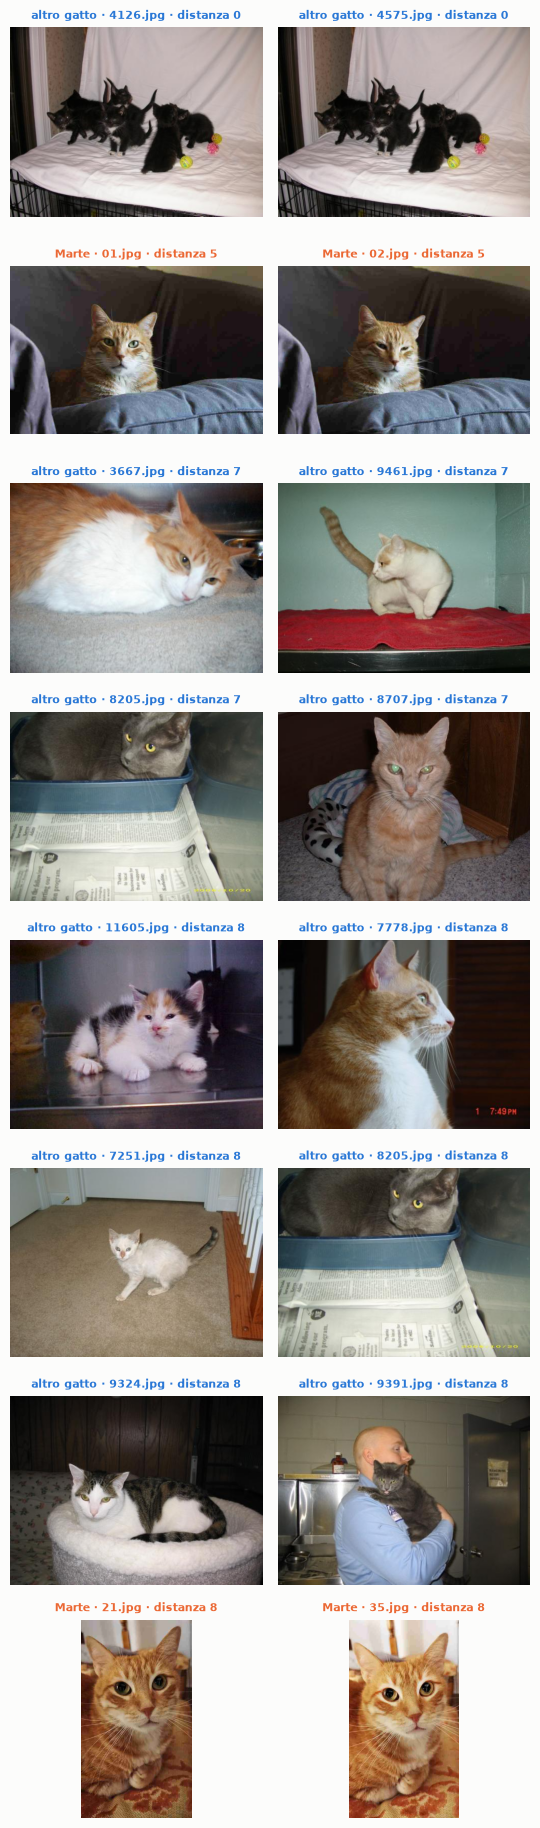

In [12]:
SOGLIA = 8 #Candidati da verificare a occhio
vicine = distanze[i, j] <= SOGLIA
candidati = sorted(zip(distanze[i, j][vicine], i[vicine], j[vicine]))

fig, axes = plt.subplots(len(candidati), 2, figsize=(5.5, 2.3 * len(candidati)))
for riga_assi, (d, a, b) in zip(axes, candidati):
    for ax, k in zip(riga_assi, (a, b)):
        with Image.open(df.percorso.iloc[k]) as img:
            ax.imshow(img.convert("RGB"))
        ax.set_title(f"{df.classe.iloc[k]} · {df.file.iloc[k]} · distanza {d}", fontsize=8, color=COLORI[df.classe.iloc[k]])
        ax.axis("off")
plt.tight_layout()
plt.show()

**Cosa troviamo.** Con distanza ≤ 8 l'hash segnala 8 coppie candidate. Guardandole una per una:
- `4126.jpg` e `4575.jpg` (altri gatti) sono **duplicati esatti**, cioè lo stesso file con due nomi;
- `01.jpg`/`02.jpg` e `21.jpg`/`35.jpg` di Marte sono **veri quasi-duplicati**: scatti a raffica della stessa scena, a pochi istanti di distanza;
- le altre coppie di altri gatti sono **falsi positivi**: foto diverse con una distribuzione simile di chiari e scuri.

**Cosa ne deduciamo.** L'hash percettivo è uno strumento di **screening**, non un verdetto: riduce 2.4 milioni di coppie a una manciata, ma la decisione finale richiede di guardare le immagini (*human in the loop*). Non esiste una soglia che separi perfettamente veri duplicati e falsi positivi: qui `21/35` (vero) ha distanza 8, mentre due coppie diverse hanno distanza 7.

Verifichiamo ora dove sono finite queste coppie nello split del primo notebook. Riproduciamo esattamente quello split: stesso seed, stessa chiamata, nessuna estrazione casuale nel mezzo.

In [13]:
torch.manual_seed(42) #Come in ImageClassifier.ipynb: seed fissato e nessuna estrazione casuale prima dello split
train_size = int(0.8 * len(cartelle))
_, val_split = torch.utils.data.random_split(cartelle, [train_size, len(cartelle) - train_size])
df["insieme_v1"] = np.where(df.index.isin(val_split.indices), "validation", "training")

print("Foto di Marte nel validation set di V1:", ((df.classe == "Marte") & (df.insieme_v1 == "validation")).sum())
coppie = [("4126.jpg", "4575.jpg"), ("01.jpg", "02.jpg"), ("21.jpg", "35.jpg")]
pd.DataFrame([{"coppia": f"{a} / {b}",
               "classe": df.loc[df.file == a, "classe"].iloc[0],
               "primo file": df.loc[df.file == a, "insieme_v1"].iloc[0],
               "secondo file": df.loc[df.file == b, "insieme_v1"].iloc[0]} for a, b in coppie])

Foto di Marte nel validation set di V1: 21


,coppia,classe,primo file,secondo file
0,4126.jpg / 4575.jpg,altro gatto,validation,training
1,01.jpg / 02.jpg,Marte,training,training
2,21.jpg / 35.jpg,Marte,training,training


**Cosa troviamo.** Il duplicato esatto degli altri gatti è **spezzato** tra training e validation: una delle 442 immagini di validazione era già stata vista in addestramento. Le due coppie di Marte sono finite entrambe in training.

**Cosa ne deduciamo.** In questo caso specifico l'effetto sulle metriche è trascurabile: un solo altro gatto, e i due scatti a raffica di Marte non toccano il validation set. Ma è stata **fortuna**, non progettazione: con un altro seed una coppia di Marte poteva finire a cavallo e regalare un "vero positivo" facile. La regola è **deduplicare prima di dividere**, oppure tenere le immagini simili nello stesso insieme: è uno split per gruppi, che in scikit-learn si fa con `StratifiedGroupKFold` (mantiene anche le proporzioni tra le classi).

## 6. Colori, luminosità e saturazione

**Perché.** Marte è un gatto **rosso tigrato**: un colore dominante diverso tra le classi è in parte un segnale **legittimo** (il gatto è davvero arancione). Ma le foto di Marte sono anche tutte scattate **nella stessa casa**, con la stessa luce e gli stessi divani: il colore può essere anche un segnale **di contesto**. Ci serve capire quanto pesa.

Per ogni immagine calcoliamo, su una versione ridotta a 64×64 (più che sufficiente per delle medie, e molto più veloce):
- media dei canali R, G, B;
- **luminosità** media;
- **saturazione** media (quanto i colori sono "vivi" rispetto al grigio, dallo spazio colore HSV).

In [14]:
def statistiche_colore(percorso):
    with Image.open(percorso) as img:
        rgb = img.convert("RGB").resize((64, 64))
    pixel = np.asarray(rgb, dtype=np.float32) / 255
    hsv = np.asarray(rgb.convert("HSV"), dtype=np.float32) / 255
    r, g, b = pixel.reshape(-1, 3).mean(axis=0)
    return {"R": r, "G": g, "B": b, "luminosita": pixel.mean(), "saturazione": hsv[..., 1].mean()}

colori = pd.DataFrame([statistiche_colore(p) for p in df.percorso], index=df.index)
df = df.join(colori)
df.groupby("classe")[["R", "G", "B", "luminosita", "saturazione"]].median().reindex(CLASSI)

,R,G,B,luminosita,saturazione
classe,,,,,
altro gatto,0.474,0.440,0.409,0.441,0.208
Marte,0.536,0.462,0.425,0.472,0.273


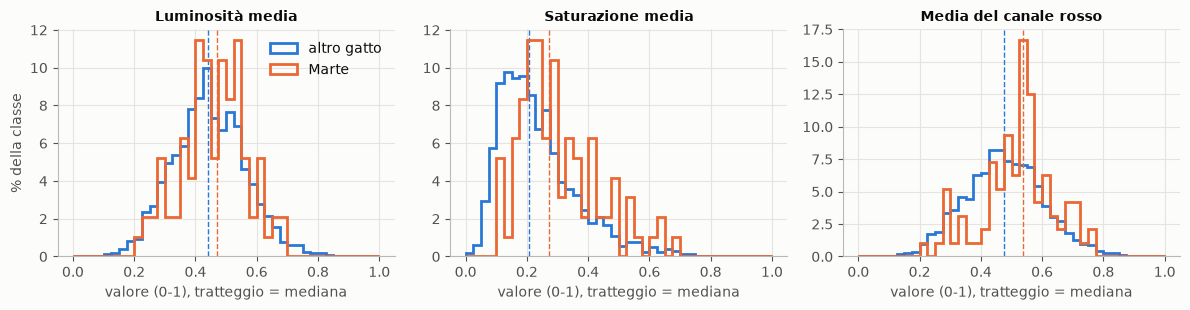

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, colonna, titolo in zip(axes, ["luminosita", "saturazione", "R"],
                               ["Luminosità media", "Saturazione media", "Media del canale rosso"]):
    bins = np.linspace(0, 1, 41)
    for classe in CLASSI:
        sotto = df.loc[df.classe == classe, colonna]
        ax.hist(sotto, bins=bins, weights=np.full(len(sotto), 100 / len(sotto)), histtype="step", lw=2,
                color=COLORI[classe], label=classe)
        ax.axvline(sotto.median(), color=COLORI[classe], lw=1, ls="--")
    ax.set_title(titolo, fontsize=10)
    ax.set_xlabel("valore (0-1), tratteggio = mediana")
axes[0].set_ylabel("% della classe")
axes[0].legend()
plt.tight_layout()
plt.show()

**Cosa troviamo.** La luminosità è molto simile tra le classi. Le foto di Marte sono invece **più sature** (mediana 0.27 contro 0.21) e con **più rosso** (0.54 contro 0.47), mentre verde e blu sono quasi uguali. Le distribuzioni però si sovrappongono molto: tanti altri gatti hanno valori identici a quelli di Marte, e tra gli altri gatti ci sono parecchi gatti rossi (lo si vede nelle griglie del primo notebook).

**Cosa ne deduciamo.** Il colore è un **indizio debole**: utile, ma da solo non separa le classi (lo verifichiamo nella sezione 8). Una parte della differenza è legittima (il pelo di Marte), una parte probabilmente è di contesto (illuminazione calda di casa, divani e coperte). Un modello che riconoscesse "la mia casa" invece di "il mio gatto" fallirebbe su una foto di Marte scattata altrove. Per misurarlo servirebbero foto di Marte in ambienti diversi, o foto di altri gatti nella stessa casa.

### Normalizzazione

Le reti pre-addestrate su ImageNet si aspettano input normalizzati con la media e la deviazione standard **di ImageNet**. Calcoliamo quelle del nostro dataset dopo lo stesso preprocessing del primo notebook (224×224, valori tra 0 e 1) per confrontarle. Qui le calcoliamo su tutto il dataset perché lo scopo è solo descrittivo.

In [16]:
somma = np.zeros(3); somma_quadrati = np.zeros(3); n_pixel = 0
for p in df.percorso:
    with Image.open(p) as img:
        x = np.asarray(img.convert("RGB").resize((224, 224), Image.BILINEAR), dtype=np.float64) / 255
    somma += x.sum(axis=(0, 1)); somma_quadrati += (x ** 2).sum(axis=(0, 1)); n_pixel += 224 * 224

media = somma / n_pixel
std = np.sqrt(somma_quadrati / n_pixel - media ** 2) #Var = E[x^2] - E[x]^2, calcolata in un solo passaggio
pd.DataFrame({"nostro dataset: media": media, "ImageNet: media": [0.485, 0.456, 0.406],
              "nostro dataset: std": std, "ImageNet: std": [0.229, 0.224, 0.225]}, index=["R", "G", "B"]).round(3)

,nostro dataset: media,ImageNet: media,nostro dataset: std,ImageNet: std
R,0.478,0.485,0.267,0.229
G,0.443,0.456,0.262,0.224
B,0.413,0.406,0.264,0.225


**Cosa ne deduciamo.** I valori del nostro dataset sono vicini a quelli di ImageNet, ma non identici. La regola pratica:
- **per una rete pre-addestrata** (ResNet, transformer) si usano le statistiche **di ImageNet**, perché i pesi sono stati imparati su input normalizzati in quel modo: cambiarle significherebbe spostare la distribuzione degli input che la rete "conosce";
- **per una rete addestrata da zero** (come CatClassifier) si possono usare quelle del proprio dataset, calcolate **solo sul training set**, per non far trapelare informazioni dal validation set.

Nel primo notebook non veniva applicata nessuna normalizzazione: è uno dei miglioramenti da introdurre.

## 7. Cosa vede davvero la rete

**Perché.** Il primo notebook usa `transforms.Resize((224, 224))`: ogni foto viene portata a 224×224 **senza rispettare le proporzioni**. Abbiamo visto che le proporzioni sono diverse tra le classi: vediamo cosa significa visivamente, e confrontiamo con l'alternativa standard `Resize(224)` + `CenterCrop(224)`, che ridimensiona il lato corto a 224 e poi ritaglia il centro.

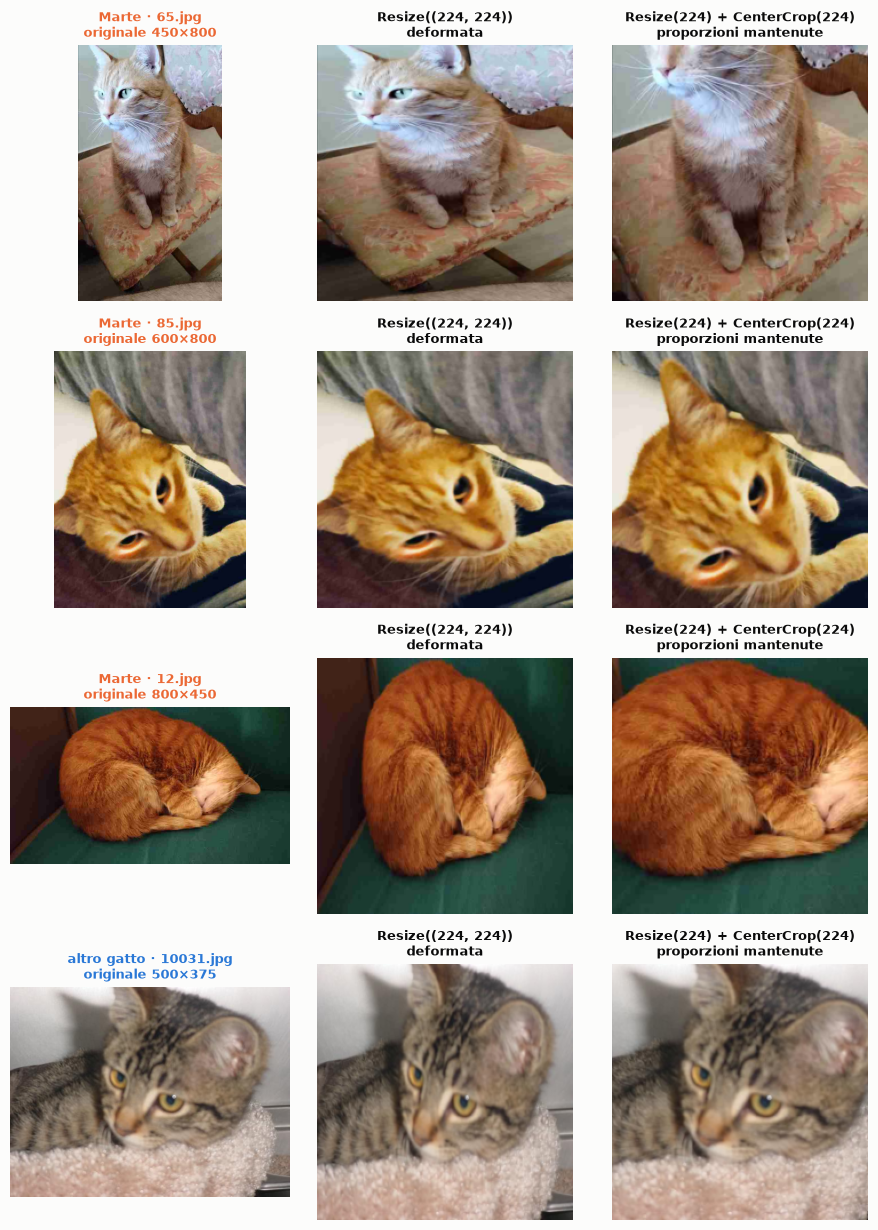

In [17]:
esempi = [ #Un esempio per ogni rapporto tipico, scelto tra le foto con quel rapporto
    ("Marte", "65.jpg"), ("Marte", "85.jpg"), ("Marte", "12.jpg"), ("altro gatto", "10031.jpg"),
]
deforma = transforms.Resize((224, 224)) #Come in ImageClassifier.ipynb
ritaglia = transforms.Compose([transforms.Resize(224), transforms.CenterCrop(224)]) #Mantiene le proporzioni

fig, axes = plt.subplots(len(esempi), 3, figsize=(9, 3.1 * len(esempi)))
for riga_assi, (classe, file) in zip(axes, esempi):
    riga = df[(df.classe == classe) & (df.file == file)].iloc[0]
    with Image.open(riga.percorso) as img:
        img = img.convert("RGB")
        viste = [(img, f"originale {riga.larghezza}×{riga.altezza}"),
                 (deforma(img), "Resize((224, 224))\ndeformata"),
                 (ritaglia(img), "Resize(224) + CenterCrop(224)\nproporzioni mantenute")]
    for ax, (vista, titolo) in zip(riga_assi, viste):
        ax.imshow(vista)
        ax.set_title(titolo, fontsize=9)
        ax.axis("off")
    riga_assi[0].set_title(f"{classe} · {riga.file}\n" + riga_assi[0].get_title(), fontsize=9, color=COLORI[classe])
plt.tight_layout()
plt.show()

**Cosa troviamo.** Con `Resize((224, 224))` le foto verticali di Marte vengono **schiacciate in altezza** (il gatto diventa tozzo), quelle in 16:9 **schiacciate in larghezza**, mentre le foto 4:3 degli altri gatti vengono deformate poco. Il *tipo* di deformazione dipende quindi dalla classe.

**Cosa ne deduciamo.**
- La deformazione è un **segnale visivo sistematico** che la rete può imparare: "gatto schiacciato in quel modo" significa quasi sempre Marte.
- `Resize + CenterCrop` elimina la deformazione, ma ha un costo: nelle foto molto verticali ritaglia via la parte alta e bassa, e a volte la testa del gatto.
- Aggiungere bande nere per rendere l'immagine quadrata (*padding* o *letterboxing*) **non risolve**: la larghezza delle bande codificherebbe di nuovo il rapporto originale.
- La soluzione più robusta in addestramento è la data augmentation **`RandomResizedCrop`**: ritaglia a caso porzioni di scala e proporzioni diverse a ogni epoca, rendendo la deformazione casuale e quindi inutile come indizio. In validazione si usa un preprocessing fisso e uguale per tutti (`Resize` + `CenterCrop`).

## 8. Test della scorciatoia

**Perché.** Finora abbiamo trovato differenze tra le classi. La domanda decisiva è: **bastano a distinguerle?** L'idea è semplice: addestriamo dei classificatori che **non vedono mai il gatto**, ma solo alcune caratteristiche tecniche della foto. Se riescono a riconoscere Marte, il dataset contiene una scorciatoia.

| Esperimento | Caratteristiche usate | Domanda |
|---|---|---|
| A. Metadati | larghezza, altezza, lato massimo, rapporto, KB, KB per megapixel, qualità JPEG | Il dataset è separabile senza guardare i pixel? |
| B. Solo proporzioni | rapporto larghezza/altezza | Quanto vale l'unica informazione geometrica che **sopravvive** a `Resize((224, 224))`, sotto forma di deformazione? |
| C. Solo colore | medie R, G, B, luminosità, saturazione | Quanto pesa il colore da solo? |

**Metodo.**
- **Modello**: `HistGradientBoostingClassifier` di scikit-learn, un insieme di alberi di decisione. È abbastanza flessibile da sfruttare qualunque regolarità presente nelle feature (anche soglie multiple, come "rapporto 9:16 *oppure* 16:9"), gestisce i valori mancanti (le GIF non hanno una qualità JPEG) e restituisce una **probabilità** invece di un sì/no. Un modello troppo semplice qui sarebbe un errore: rischierebbe di *sottostimare* la scorciatoia e farci concludere che il dataset è più pulito di quanto sia.
- **Valutazione**: **cross-validation stratificata a 5 fold** con `cross_val_predict`. Il dataset viene diviso in 5 parti con le stesse proporzioni di classi, e ogni immagine riceve una probabilità da un modello che **non l'ha vista** in addestramento. Così tutte le 96 foto di Marte contribuiscono alla valutazione, invece delle circa 20 di un singolo split.
- **Metriche**: con classi così sbilanciate non usiamo una soglia fissa, ma la **curva precision-recall**, che mostra tutti i compromessi possibili tra "trovare tante foto di Marte" e "sbagliare poco". Ne riassumiamo due numeri:
  - **PR-AUC** (area sotto la curva): 1 è perfetto, mentre un classificatore che tira a indovinare vale quanto la frequenza di Marte, **0.044**;
  - **recall con precisione ≥ 90%**: quante foto di Marte trova il modello sbagliando al massimo una volta su dieci. È il numero più adatto per un confronto, solo indicativo, con la ResNet del primo notebook, che aveva precisione 100%.

In [18]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import precision_recall_curve, average_precision_score, precision_score, recall_score

y = df.etichetta.to_numpy() #1 = Marte
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

esperimenti = {
    "A. Metadati": ["larghezza", "altezza", "lato_max", "rapporto", "kb", "kb_per_mpx", "qualita_jpeg"],
    "B. Solo proporzioni": ["rapporto"],
    "C. Solo colore": ["R", "G", "B", "luminosita", "saturazione"],
}

risultati, curve = [], {}
for nome, colonne in esperimenti.items():
    #Ogni immagine riceve la probabilità di essere Marte da un modello che non l'ha vista in addestramento
    prob = cross_val_predict(HistGradientBoostingClassifier(random_state=42), df[colonne], y,
                             cv=cv, method="predict_proba")[:, 1]
    precisione, recall, _ = precision_recall_curve(y, prob)
    curve[nome] = (precisione, recall)
    risultati.append({"esperimento": nome,
                      "PR-AUC": average_precision_score(y, prob),
                      "recall con precisione >= 90%": recall[precisione >= 0.9].max(),
                      "recall con precisione >= 50%": recall[precisione >= 0.5].max()})

risultati = pd.DataFrame(risultati).set_index("esperimento")
risultati.loc["Riferimento: caso"] = [y.mean(), 0, 0]
risultati.round(3)

,PR-AUC,recall con precisione >= 90%,recall con precisione >= 50%
esperimento,,,
A. Metadati,1.000,1.000,1.00
B. Solo proporzioni,0.547,0.448,0.49
C. Solo colore,0.109,0.000,0.00
Riferimento: caso,0.043,0.000,0.00


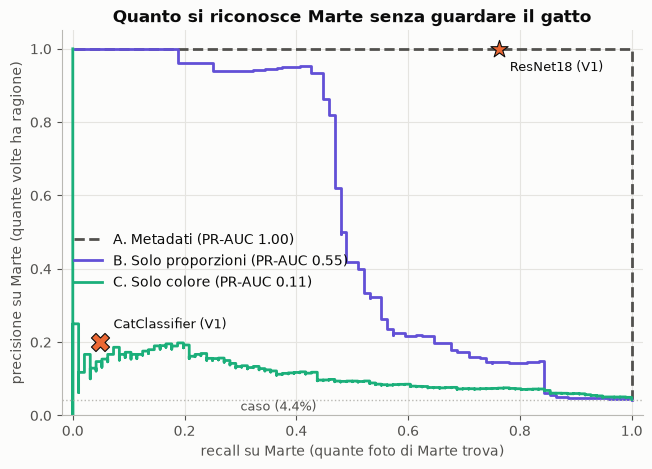

In [19]:
fig, ax = plt.subplots(figsize=(7.5, 5))
stili = {"A. Metadati": ("#52514e", "--"), "B. Solo proporzioni": ("#6250d6", "-"), "C. Solo colore": ("#1baf7a", "-")}
for nome, (precisione, recall) in curve.items():
    colore, tratto = stili[nome]
    ax.plot(recall, precisione, color=colore, ls=tratto, lw=2, drawstyle="steps-post",
            label=f"{nome} (PR-AUC {risultati.loc[nome, 'PR-AUC']:.2f})")
ax.axhline(y.mean(), color="#b9b8b3", lw=1, ls=":")
ax.text(0.3, y.mean() - 0.03, "caso (4.4%)", color="#52514e", fontsize=9)

#Le due reti del primo notebook, per orientarsi (valutate su un solo split di 442 immagini, non in cross-validation)
for nome, (r, pr), marker, spostamento in [("ResNet18 (V1)", (0.762, 1.0), "*", (8, -16)),
                                            ("CatClassifier (V1)", (0.048, 0.20), "X", (10, 10))]:
    ax.scatter(r, pr, s=170, marker=marker, color=COLORI["Marte"], edgecolors="#0b0b0b", linewidths=0.8, zorder=5)
    ax.annotate(nome, (r, pr), xytext=spostamento, textcoords="offset points", fontsize=9, color="#0b0b0b")

ax.set_xlim(-0.02, 1.02); ax.set_ylim(0, 1.05)
ax.set_xlabel("recall su Marte (quante foto di Marte trova)")
ax.set_ylabel("precisione su Marte (quante volte ha ragione)")
ax.set_title("Quanto si riconosce Marte senza guardare il gatto")
ax.legend(loc="center left", bbox_to_anchor=(0, 0.4))
plt.show()

In [20]:
#Le regole più semplici possibili: un albero con una sola domanda su una sola caratteristica
for colonna in ["lato_max", "qualita_jpeg"]:
    albero = DecisionTreeClassifier(max_depth=1, random_state=42)
    previsioni = cross_val_predict(albero, df[[colonna]], y, cv=cv)
    print(f"{colonna}: precisione {precision_score(y, previsioni):.0%}, recall {recall_score(y, previsioni):.0%}")
    print(export_text(albero.fit(df[[colonna]], y), feature_names=[colonna], class_names=["altro gatto", "Marte"]))

nove_sedicesimi = (df.rapporto - 9 / 16).abs() < 0.01
print("Foto in 9:16 ->", pd.crosstab(df.classe, nove_sedicesimi).reindex(CLASSI)[True].to_dict())

lato_max: precisione 100%, recall 100%
|--- lato_max <= 585.50
|   |--- class: altro gatto
|--- lato_max >  585.50
|   |--- class: Marte

qualita_jpeg: precisione 100%, recall 100%
|--- qualita_jpeg <= 29.85
|   |--- class: Marte
|--- qualita_jpeg >  29.85
|   |--- class: altro gatto

Foto in 9:16 -> {'altro gatto': 10, 'Marte': 35}


**Cosa troviamo.**
- **A. Metadati: separazione perfetta (PR-AUC 1.00).** Non serve nemmeno un modello: **due regole indipendenti**, ciascuna da sola, classificano correttamente tutte le 2207 immagini:
  - *lato massimo > 585 pixel → Marte*;
  - *qualità JPEG ≤ 30 → Marte*.
- **B. Solo proporzioni: PR-AUC 0.55**, cioè 12 volte il caso. Con il solo rapporto larghezza/altezza il modello trova **il 45% delle foto di Marte con una precisione di almeno il 90%**. Il motivo è nell'ultima riga: il 36% delle foto di Marte è in formato 9:16 (telefono in verticale), un formato che compare in appena **10 foto su 2111** degli altri gatti.
- **C. Solo colore: PR-AUC 0.11.** Non raggiunge mai nemmeno il 50% di precisione: il colore da solo produce troppi falsi allarmi per essere utile.

**Cosa ne deduciamo.** Questo è il risultato più importante del notebook.
1. **Il dataset è separabile perfettamente, e in due modi diversi, per motivi che non c'entrano con il gatto**: risoluzione e compressione. Metriche alte su questo dataset **non bastano a dimostrare** che un modello riconosca il gatto, finché non si escludono le scorciatoie.
2. **Quali di queste informazioni restano disponibili alla rete dopo `Resize((224, 224))`?** Disponibili, non necessariamente usate:
   - le **dimensioni assolute** no: vengono cancellate;
   - la **deformazione** sì, e da sola basta a riconoscere quasi metà delle foto di Marte con alta precisione (esperimento B);
   - gli **artefatti di compressione** forse (sezione 4): qui abbiamo misurato la qualità JPEG dai metadati, ma quanto ne resti nei pixel dopo il ridimensionamento, e quanto una rete ne sia influenzata, questo test non può dirlo.
3. **Cosa possiamo dire della ResNet? Poco, e con cautela.** Questi classificatori dimostrano che le scorciatoie **esistono nel dataset**, non che la ResNet le **usi**. Una rete addestrata su queste immagini potrebbe riconoscere il gatto, sfruttare una o più scorciatoie, o combinare le due cose: le correlazioni osservate qui non permettono di distinguere questi casi. Anche la posizione della ResNet (stella) e di CatClassifier (croce) rispetto alle curve va letta solo come indicazione, perché i protocolli sono diversi: le due reti sono state valutate su un singolo split con 21 foto di Marte, le curve in cross-validation su tutte le 96. Per capire cosa influenza davvero un modello bisogna **modificare le immagini in modo controllato e misurare come cambiano le sue previsioni**: lo facciamo per la compressione nella prossima sezione.

> Questo fenomeno si chiama **shortcut learning**: un modello impara la regola più facile che separa i dati di addestramento, anche se non è quella che intendevamo. È uno dei problemi più comuni nei progetti reali di computer vision. Un esempio noto: modelli che dovevano riconoscere la polmonite dalle radiografie hanno imparato a riconoscere **l'ospedale di provenienza** dell'immagine, perché la frequenza della malattia era diversa tra gli ospedali.

## 9. Esperimento sui pixel: ricompressione controllata

**Perché.** Le sezioni precedenti dicono che il dataset *contiene* scorciatoie. Per sapere se un modello ne è *influenzato* bisogna guardare il modello, non il dataset. Il modo più semplice e pulito è un **esperimento controllato**: prendere le stesse immagini, cambiare **una sola cosa** e misurare come cambiano le previsioni.

**Cosa facciamo.**
- Usiamo la **ResNet18 già addestrata** nel primo notebook, caricando i suoi pesi da file, **senza riaddestrarla**.
- Usiamo lo **stesso validation set** (le stesse 442 immagini, ricostruite nella sezione 5) e lo **stesso preprocessing** (`Resize((224, 224))` + `ToTensor`, nessuna normalizzazione).
- Ogni immagine viene valutata in tre versioni:
  1. **originale**;
  2. **ricompressa a qualità 75**: è il livello tipico degli altri gatti. Serve da **controllo**: misura quanto la rete reagisce a una ricompressione "qualsiasi";
  3. **ricompressa a qualità 20**: è il livello delle foto di Marte (sezione 4).

  La ricompressione avviene alla risoluzione originale, prima del ridimensionamento, cioè dove sono nati gli artefatti.

**Cosa ci aspettiamo.** Se la rete associasse gli artefatti di compressione forte a Marte, con la qualità 20 molti altri gatti dovrebbero diventare "più Marte" (probabilità in aumento, nuovi falsi positivi), e molto più che con la qualità 75.

**Cosa questo esperimento non può dire.**
- Una variazione delle previsioni mostra che la rete è **sensibile** alla compressione, non che la compressione sia la **causa** delle sue prestazioni.
- L'assenza di variazioni non esclude che la rete abbia imparato altre scorciatoie (le proporzioni, il contesto).
- Le foto di Marte, già a qualità 20, subiscono una **doppia compressione**, che non equivale a quella originale.

In [21]:
from io import BytesIO
import torch.nn as nn
from torchvision import models

PESI = Path("resnet18_v1.pth") #Salvati da ImageClassifier.ipynb con torch.save(resnet_model.state_dict(), "resnet18_v1.pth")

resnet = models.resnet18(weights=None) #Stessa architettura del primo notebook: i pesi li carichiamo dal file
resnet.fc = nn.Linear(resnet.fc.in_features, 2)
resnet.load_state_dict(torch.load(PESI, map_location="cpu"))
resnet.eval() #Modalità valutazione: niente aggiornamento dei pesi, batch normalization con le statistiche imparate

preprocess_v1 = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor()]) #Identico al primo notebook

def ricomprimi(img, qualita):
    #Salva l'immagine come JPEG in memoria con la qualità indicata e la rilegge: stessa risoluzione, nuovi artefatti
    buffer = BytesIO()
    img.save(buffer, format="JPEG", quality=qualita)
    buffer.seek(0)
    return Image.open(buffer).convert("RGB")

def probabilita_marte(percorsi, qualita=None, batch=32):
    #Probabilità che la rete assegna a "Marte" per ogni immagine, con o senza ricompressione
    risultati = []
    with torch.no_grad():
        for inizio in range(0, len(percorsi), batch):
            tensori = []
            for p in percorsi[inizio:inizio + batch]:
                with Image.open(p) as img:
                    img = img.convert("RGB") #Come fa ImageFolder
                    if qualita is not None:
                        img = ricomprimi(img, qualita)
                    tensori.append(preprocess_v1(img))
            logits = resnet(torch.stack(tensori))
            risultati.append(torch.softmax(logits, dim=1)[:, 1]) #Colonna 1 = Marte
    return torch.cat(risultati).numpy()

val = df[df.insieme_v1 == "validation"].copy()
VARIANTI = {"originale": None, "qualità 75 (controllo)": 75, "qualità 20 (come Marte)": 20}
for nome, qualita in VARIANTI.items():
    val[nome] = probabilita_marte(list(val.percorso), qualita)
print("Immagini di validazione:", val.classe.value_counts().reindex(CLASSI).to_dict())

Immagini di validazione: {'altro gatto': 421, 'Marte': 21}


In [22]:
#Prima riga = controllo: sulle immagini originali dobbiamo ritrovare i risultati del primo notebook
altri, marte = val.classe == "altro gatto", val.classe == "Marte"
riepilogo = []
for nome in VARIANTI:
    previsto_marte = val[nome] >= 0.5 #Con 2 classi, la classe prevista è quella con probabilità > 0.5
    riepilogo.append({
        "variante": nome,
        "altri gatti previsti Marte (falsi positivi)": int((previsto_marte & altri).sum()),
        "Marte riconosciuti": f"{int((previsto_marte & marte).sum())} su {int(marte.sum())}",
        "previsioni cambiate rispetto all'originale": int((previsto_marte != (val["originale"] >= 0.5)).sum()),
        "% altri gatti con P(Marte) aumentata": (val.loc[altri, nome] > val.loc[altri, "originale"]).mean() * 100,
        "aumento mediano di P(Marte), altri gatti": (val.loc[altri, nome] / val.loc[altri, "originale"]).median(),
        "P(Marte) mediana, altri gatti": val.loc[altri, nome].median(),
        "P(Marte) mediana, Marte": val.loc[marte, nome].median(),
    })
pd.DataFrame(riepilogo).set_index("variante")

,altri gatti previsti Marte (falsi positivi),Marte riconosciuti,previsioni cambiate rispetto all'originale,% altri gatti con P(Marte) aumentata,"aumento mediano di P(Marte), altri gatti","P(Marte) mediana, altri gatti","P(Marte) mediana, Marte"
variante,,,,,,,
originale,0,16 su 21,0,0.000,1.000,7.110e-05,0.854
qualità 75 (controllo),0,16 su 21,0,51.544,1.000,7.192e-05,0.853
qualità 20 (come Marte),1,16 su 21,1,81.710,2.625,1.835e-04,0.855


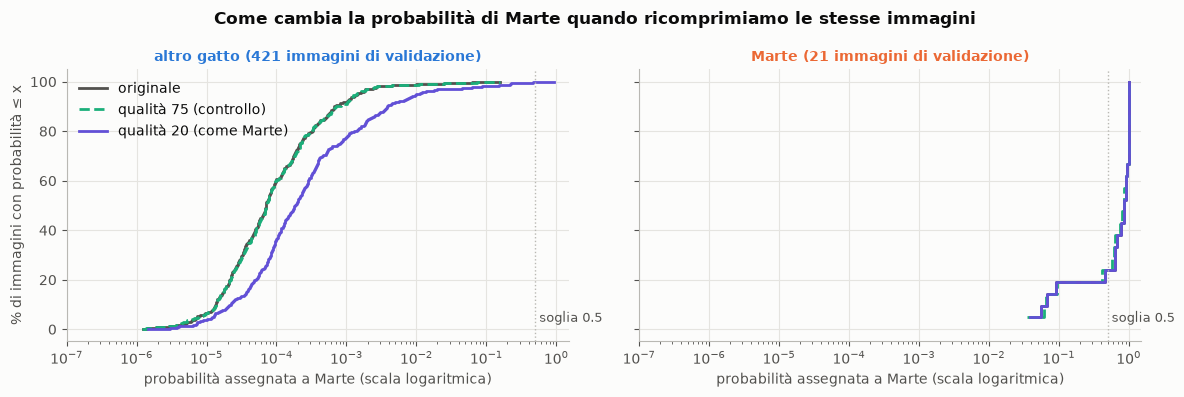

In [23]:
#Distribuzione cumulativa di P(Marte): per ogni valore x, quale percentuale di immagini ha probabilità <= x.
#Scala logaritmica perché per gli altri gatti le probabilità sono vicinissime a zero.
stili = {"originale": ("#52514e", "-"), "qualità 75 (controllo)": ("#1baf7a", "--"), "qualità 20 (come Marte)": ("#6250d6", "-")}
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, classe in zip(axes, CLASSI):
    sotto = val[val.classe == classe]
    for nome in VARIANTI:
        valori = np.sort(np.clip(sotto[nome].to_numpy(), 1e-7, 1))
        colore, tratto = stili[nome]
        ax.step(valori, np.arange(1, len(valori) + 1) / len(valori) * 100, where="post", color=colore, ls=tratto, lw=2, label=nome)
    ax.axvline(0.5, color="#b9b8b3", lw=1, ls=":")
    ax.text(0.5, 3, " soglia 0.5", color="#52514e", fontsize=9)
    ax.set_xscale("log")
    ax.set_xlim(1e-7, 1.5)
    ax.set_xlabel("probabilità assegnata a Marte (scala logaritmica)")
    ax.set_title(f"{classe} ({len(sotto)} immagini di validazione)", fontsize=10, color=COLORI[classe])
axes[0].set_ylabel("% di immagini con probabilità ≤ x")
axes[0].legend(loc="upper left")
fig.suptitle("Come cambia la probabilità di Marte quando ricomprimiamo le stesse immagini", fontweight="bold")
plt.tight_layout()
plt.show()

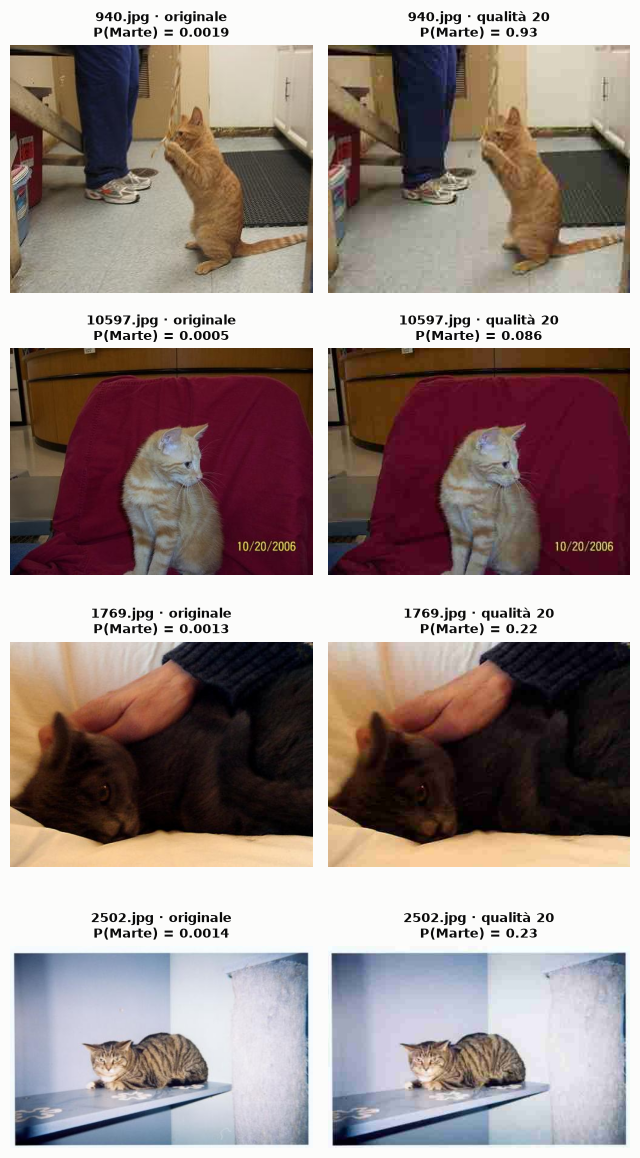

In [24]:
#Gli altri gatti la cui probabilità di Marte aumenta di più con la qualità 20: vediamo come cambiano le immagini
val["aumento_q20"] = np.log10(val["qualità 20 (come Marte)"].clip(1e-7)) - np.log10(val["originale"].clip(1e-7))
peggiori = val[altri].nlargest(4, "aumento_q20")

fig, axes = plt.subplots(len(peggiori), 2, figsize=(6.5, 3 * len(peggiori)))
for riga_assi, (_, riga) in zip(axes, peggiori.iterrows()):
    with Image.open(riga.percorso) as img:
        img = img.convert("RGB")
        viste = [(img, "originale", riga["originale"]), (ricomprimi(img, 20), "qualità 20", riga["qualità 20 (come Marte)"])]
    for ax, (vista, titolo, prob) in zip(riga_assi, viste):
        ax.imshow(vista)
        ax.set_title(f"{riga.file} · {titolo}\nP(Marte) = {prob:.2g}", fontsize=9)
        ax.axis("off")
plt.tight_layout()
plt.show()

**Cosa troviamo.**
- **Il controllo di partenza è superato.** Sulle immagini originali la rete trova 16 foto di Marte su 21 con 0 falsi positivi, esattamente come nel primo notebook: i pesi caricati e il validation set ricostruito sono quelli giusti.
- **Qualità 75 (controllo): nessun effetto.** Nessuna previsione cambia, le curve coincidono con quelle originali, e la probabilità di Marte sale per il 51.5% degli altri gatti e scende per gli altri, con un fattore mediano di 1.00: è puro rumore. La rete **non** reagisce a una ricompressione qualsiasi.
- **Qualità 20: uno spostamento sistematico verso Marte.** Per l'**81.7%** degli altri gatti la probabilità di Marte aumenta, con un fattore mediano di **2.6** (la mediana passa da 0.00007 a 0.00018). Per alcune immagini l'aumento è di due o tre ordini di grandezza: `940.jpg`, un gatto rosso, passa da 0.002 a **0.93** e diventa l'unico nuovo falso positivo.
- **Le foto di Marte non cambiano** (16 su 21 in tutte le versioni): una seconda compressione a qualità 20 aggiunge poco a foto già compresse così.

**Cosa ne deduciamo.**
- La ResNet è **sensibile specificamente alla compressione forte**, non alla ricompressione in sé (lo dice il controllo a qualità 75), e la sposta **nella direzione di Marte**. È quello che ci si aspetterebbe se la rete avesse associato, almeno in parte, gli artefatti di compressione alla classe Marte.
- **In termini di decisioni, però, l'effetto è piccolo**: cambia 1 previsione su 421, e quasi tutte le probabilità restano lontanissime dalla soglia di 0.5. La compressione da sola non basta a far scambiare un gatto qualsiasi per Marte: per questo modello sembra un **indizio secondario**, non il fattore principale delle sue decisioni.
- L'unica immagine che supera la soglia è un gatto rosso, come Marte, e anche tra le altre che salgono di più ce n'è uno. Sembra che la compressione si **sommi** a somiglianze già presenti (colore del pelo, posa) piuttosto che agire da sola, ma un solo caso non permette di generalizzare.

**Limiti.** Questo esperimento mostra una **sensibilità**, non un rapporto di causa: non dice quanto delle prestazioni della ResNet dipenda dalla compressione. Riguarda un solo modello addestrato una sola volta, su un validation set con 21 foto di Marte. E non dice nulla sulle altre scorciatoie (proporzioni, contesto domestico), che vanno verificate con esperimenti analoghi.

## 10. Conclusioni e piano per i prossimi esperimenti

| Problema | Evidenza | Rischio | Azione |
|---|---|---|---|
| **Sbilanciamento** 22:1 | sezione 2 | accuratezza inutile, modello che ignora Marte | metriche su Marte (precisione, recall, F1, PR-AUC); pesi delle classi nella loss |
| **Valutazione rumorosa** | ~20 foto di Marte in validazione | differenze tra modelli dovute al caso | cross-validation stratificata a 5 fold |
| **Fonti diverse**: risoluzione | sezione 3, esperimento A | separazione perfetta (lato massimo > 585 px) | ridimensionare tutte le immagini allo **stesso lato massimo** *prima* di tutto il resto |
| **Fonti diverse**: compressione | sezione 4, esperimento A, sezione 9 | separazione perfetta nei metadati (qualità JPEG stimata ~20 contro ~75); la ResNet è sensibile alla compressione forte (probabilità di Marte ×2.6 in mediana), ma con effetto piccolo sulle decisioni (1 previsione su 421) | ricomprimere **tutte** le immagini con la stessa qualità, o usare compressione JPEG casuale come augmentation |
| **Proporzioni diverse** | sezioni 3 e 7, esperimento B | la sola deformazione trova il 45% delle foto di Marte con precisione ≥ 90% | `RandomResizedCrop` in training, `Resize` + `CenterCrop` in validazione |
| **Duplicati e scatti a raffica** | sezione 5 | leakage tra training e validation | rimuovere i duplicati esatti; tenere gli scatti simili nello stesso fold |
| **Contesto domestico** | sezione 6 | la rete riconosce la casa, non il gatto | idealmente nuove foto: Marte altrove, altri gatti in casa |
| **File anomali** | sezione 4 | errori con altri caricatori | verificare il formato dal contenuto; conversione esplicita in RGB |
| **Nessuna normalizzazione** | sezione 6 | input diversi da quelli attesi dalle reti pre-addestrate | statistiche di ImageNet per i modelli pre-addestrati |

### Il prossimo passo

Con queste informazioni possiamo progettare l'esperimento con il **transformer** in modo che il confronto sia onesto:
1. **dataset ripulito**: duplicati rimossi, risoluzione e compressione uniformate, scatti a raffica raggruppati;
2. **stesso protocollo per tutti i modelli** (CatClassifier, ResNet18, transformer): cross-validation stratificata a 5 fold, stesse metriche, stessa normalizzazione;
3. **test controllati sulle scorciatoie**, come quello della sezione 9: ripetere la ricompressione per ogni modello e aggiungere un test analogo sulle proporzioni (stesse immagini con rapporto uniformato tramite ritaglio centrale), per vedere quanto della performance dipende dalla forma della foto invece che dal gatto.

In questo modo la domanda non sarà più solo "quale modello ha il numero più alto?", ma "quale modello riconosce davvero Marte?".